# 05 — Değerlendirme grafikleri ve final tablo

**Sahibi:** Öğrenci 3 (TabNet & Comparative Analytics)

Bu notebook plan madde 9 / Adım 8'i karşılar: Grafik 4-5-6 ve final metrik
tablosu. Modeller `models/preds/*.csv` üzerinden **dinamik** olarak yüklenir:
şu an sadece `tabnet.csv` var (v0 sürümü); Öğrenci 2'nin `perceptron.csv` ve
`lgbm.csv` dosyaları `main`'e merge olunca bu notebook **değişmeden** yeniden
çalıştırılır ve otomatik olarak 3 modelle dolar. Grafik 1-3'ün final halleri
(Öğrenci 1'in `clean_*`/`nan_mask`/`train_smote`/`train_ctgan` dosyalarını
gerektirir) henüz merge edilmediği için bu notebook'a eklenmedi.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## Mevcut tahminleri yükle

In [2]:
import numpy as np
import pandas as pd

from src.config import IMPORTANCE_DIR, REPORTS_DIR
from src.metrics import evaluate, load_preds
from src.plots import plot_cm_grid, plot_importance_and_masks, plot_roc_pr, save_fig, set_style

set_style()

MODEL_NAMES = ["perceptron", "lgbm", "tabnet"]
preds = {}
for name in MODEL_NAMES:
    try:
        preds[name] = load_preds(name)
        print(f"{name}: yüklendi ({len(preds[name])} satır)")
    except FileNotFoundError as e:
        print(f"{name}: henüz yok -> {e}")

list(preds)

perceptron: henüz yok -> C:\Users\kdrgn\DataScienceProject\models\preds\perceptron.csv not found; its owner has not pushed it yet.
lgbm: henüz yok -> C:\Users\kdrgn\DataScienceProject\models\preds\lgbm.csv not found; its owner has not pushed it yet.
tabnet: yüklendi (4495 satır)


['tabnet']

## Grafik 5: ROC ve Precision-Recall

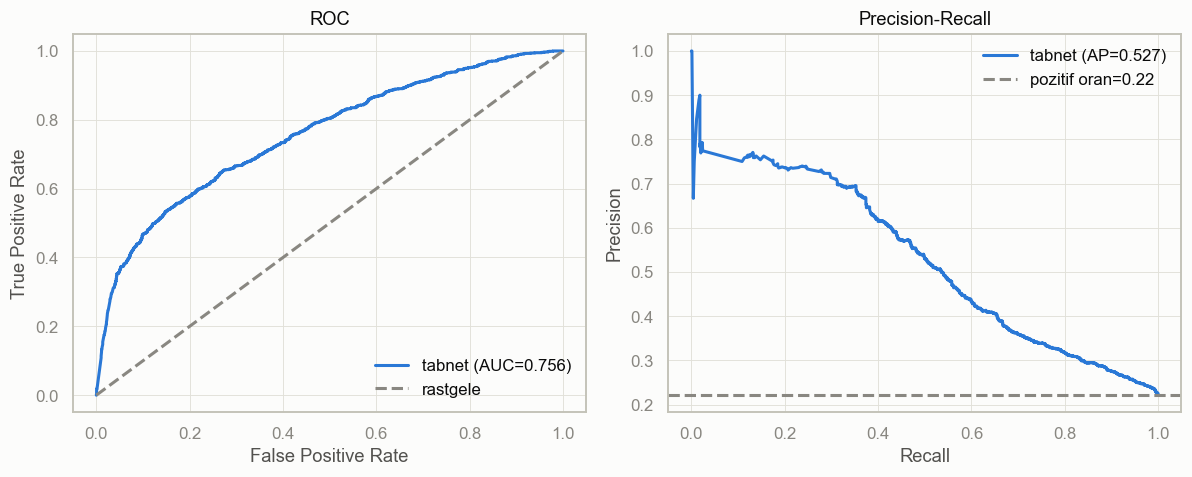

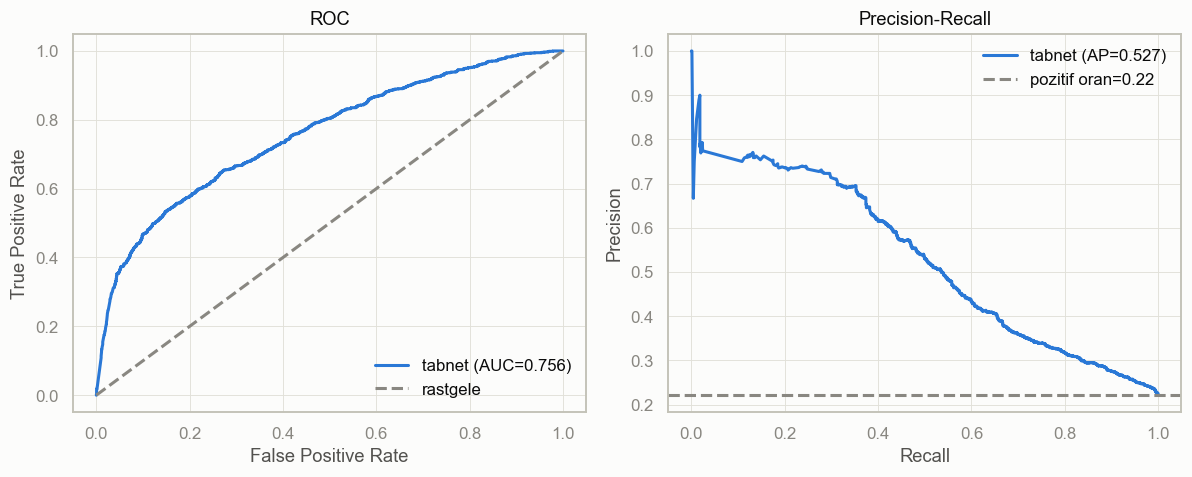

In [3]:
models_score = {
    name: (df["y_true"].to_numpy(), df["y_score"].to_numpy()) for name, df in preds.items()
}
fig = plot_roc_pr(models_score)
save_fig(fig, "fig5_roc_pr")
fig

## Grafik 6: Normalize confusion matrix

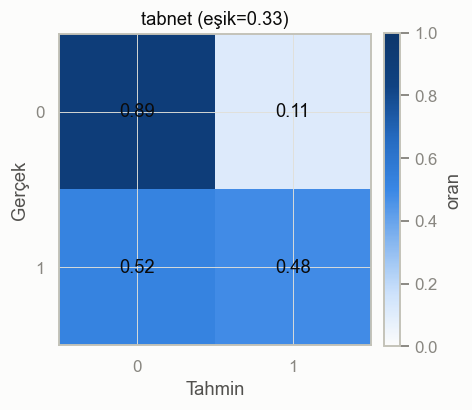

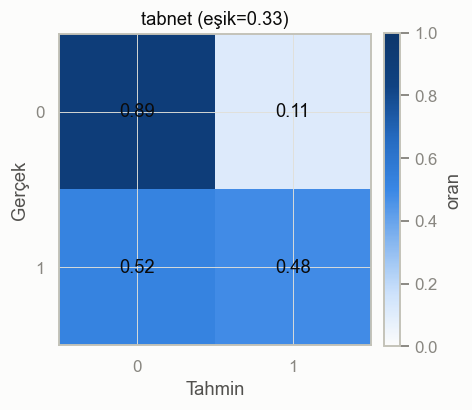

In [4]:
models_pred = {
    name: (df["y_true"].to_numpy(), df["y_pred"].to_numpy(), df["threshold"].iloc[0])
    for name, df in preds.items()
}
fig = plot_cm_grid(models_pred)
save_fig(fig, "fig6_confusion")
fig

## Grafik 4: TabNet maskeleri + TabNet önemi + LGBM önemi

LGBM paneli `models/importance/lgbm_importance.csv` gelince otomatik dolacak;
gelene kadar TabNet'in kendi sırasıyla sıfır/placeholder gösterilir.

lgbm_importance.csv henüz yok, placeholder (sıfır) kullanılıyor


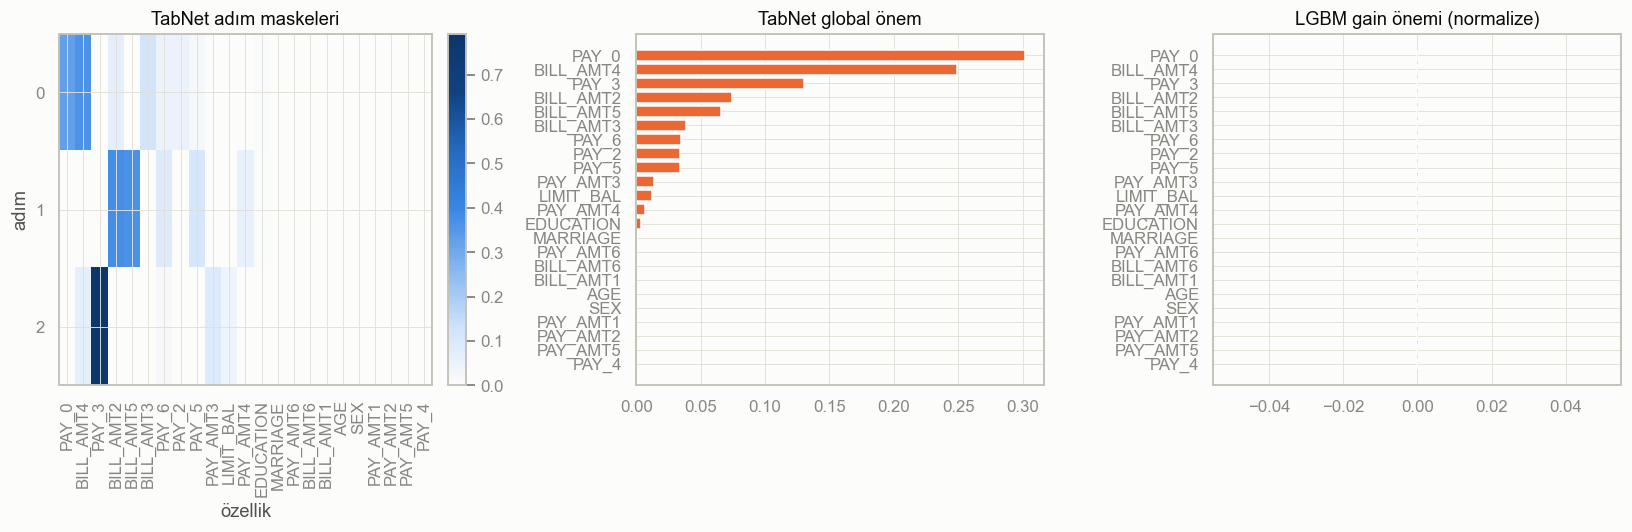

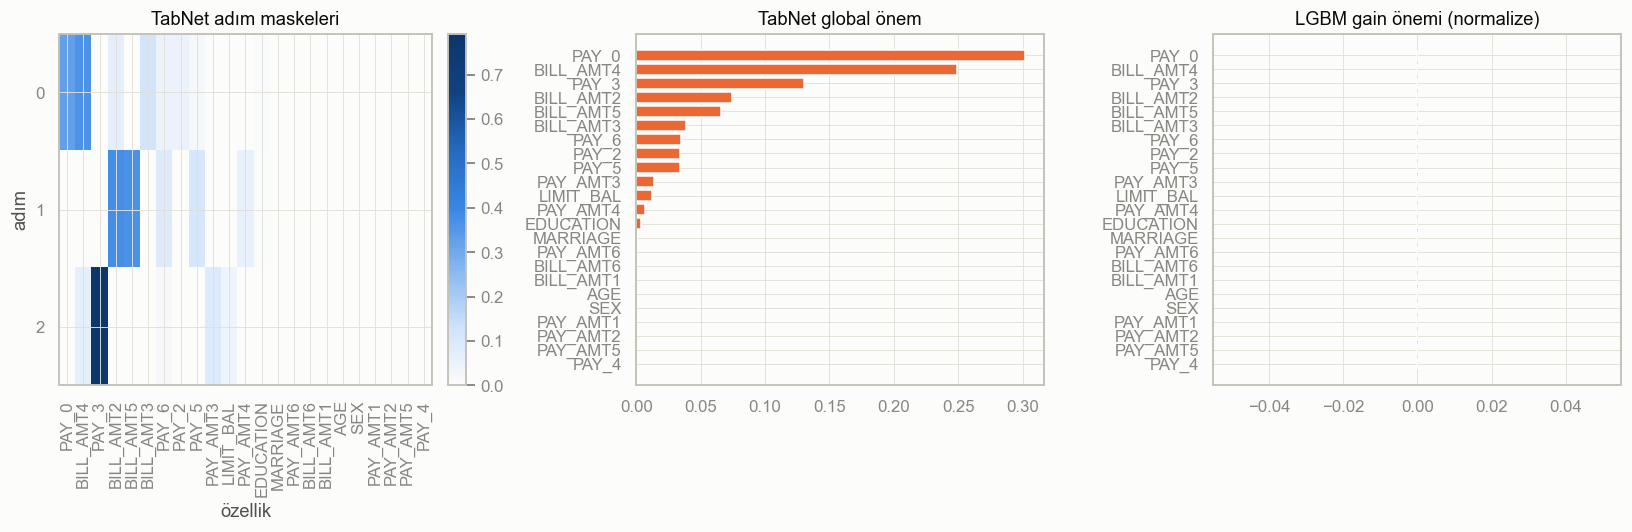

In [5]:
tabnet_global = pd.read_csv(IMPORTANCE_DIR / "tabnet_global.csv").set_index("feature")
masks_npz = np.load(IMPORTANCE_DIR / "tabnet_masks.npz", allow_pickle=True)
step_masks, mask_features = masks_npz["masks"], list(masks_npz["features"])

order = tabnet_global["importance"].reindex(mask_features).to_numpy().argsort()[::-1]
feature_order = [mask_features[i] for i in order]
tabnet_importance = tabnet_global["importance"].reindex(mask_features).to_numpy()[order]
step_masks_ordered = step_masks[:, order]

lgbm_path = IMPORTANCE_DIR / "lgbm_importance.csv"
if lgbm_path.exists():
    lgbm_df = pd.read_csv(lgbm_path).set_index("feature")
    lgbm_importance = lgbm_df["gain"].reindex(feature_order).to_numpy()
    print("lgbm_importance.csv yüklendi")
else:
    lgbm_importance = np.zeros(len(feature_order))
    print("lgbm_importance.csv henüz yok, placeholder (sıfır) kullanılıyor")

fig = plot_importance_and_masks(step_masks_ordered, tabnet_importance, lgbm_importance, feature_order)
save_fig(fig, "fig4_importance_masks")
fig

## Final metrik tablosu

In [6]:
rows = []
for name, df in preds.items():
    m = evaluate(df["y_true"], df["y_score"], df["y_pred"])
    m["model"] = name
    m["threshold"] = df["threshold"].iloc[0]
    rows.append(m)

final_metrics = pd.DataFrame(rows)[
    ["model", "macro_f1", "weighted_f1", "roc_auc", "pr_auc", "accuracy", "threshold"]
].sort_values("macro_f1", ascending=False)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
final_metrics.to_csv(REPORTS_DIR / "final_metrics.csv", index=False)
final_metrics

,model,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy,threshold
0,tabnet,0.692971,0.793044,0.756486,0.527152,0.797998,0.327701
